In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("loan-train.csv")
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1609,LP009965,Male,No,3+,Graduate,Yes,13658,9822.0,323.0,180.0,0.0,Urban,N
1610,LP009966,Male,Yes,0,Graduate,No,13683,2223.0,182.0,360.0,1.0,Semiurban,Y
1611,LP009970,Male,Yes,3+,Not Graduate,Yes,19409,768.0,222.0,360.0,0.0,Urban,N
1612,LP009977,Female,Yes,2,Graduate,Yes,8997,1354.0,355.0,360.0,0.0,Rural,Y


In [3]:
print("------START--------")

------START--------


In [4]:
# ==================================================
# LOAN ELIGIBILITY DATA ANALYSIS AND EDA
# ==================================================
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# ==================================================
# STEP 2: LOAD DATASET
# ==================================================
df = pd.read_csv("loan-train.csv")

print("\nFirst 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())


First 5 Rows:
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2    

In [6]:
# ==================================================
# STEP 3: BASIC DATASET INFORMATION
# ==================================================

print("\nDataset Shape:")
print(df.shape)

print("\nNumber of Rows:")
print(df.shape[0])

print("\nNumber of Columns:")
print(df.shape[1])

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nComplete Statistical Summary:")
print(df.describe(include="all"))


Dataset Shape:
(1614, 13)

Number of Rows:
1614

Number of Columns:
13

Column Names:
Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   16


Missing Values in Each Column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Total Missing Values:
149

Missing Values Percentage:
Loan_ID              0.000000
Gender               0.805452
Married              0.185874
Dependents           0.929368
Education            0.000000
Self_Employed        1.982652
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           1.363073
Loan_Amount_Term     0.867410
Credit_History       3.097893
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64


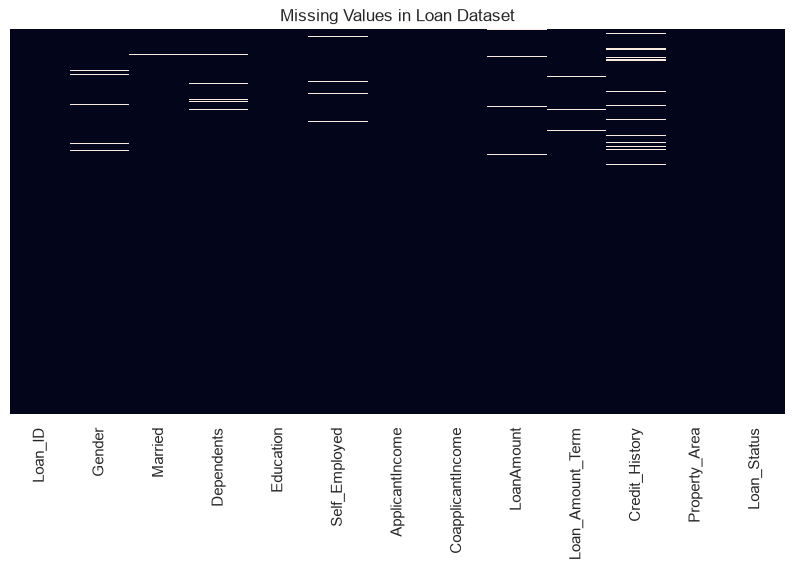

In [7]:
# ==================================================
# STEP 4: CHECK MISSING VALUES
# ==================================================

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df)) * 100)

# Visualize Missing Values

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Loan Dataset")
plt.show()

In [8]:
# ==================================================
# STEP 5: CHECK DUPLICATES
# ==================================================

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

# Remove duplicates

df.drop_duplicates(inplace=True)

print("\nShape After Removing Duplicates:")
print(df.shape)


Total Duplicate Rows:
0

Shape After Removing Duplicates:
(1614, 13)


In [9]:
# ==================================================
# STEP 6: DATA CLEANING
# ==================================================

# Remove extra spaces from column names
df.columns = df.columns.str.strip()
# Replace question marks with missing values
df.replace("?", np.nan, inplace=True)

# Convert numeric columns
numeric_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numeric values using median

for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using mode

# Select categorical columns
categorical_columns = df.select_dtypes(include=['object', 'str']).columns

# Select numerical columns
numerical_columns = df.select_dtypes(include=['number']).columns

print("Categorical Columns:", categorical_columns.tolist())
print("Numerical Columns:", numerical_columns.tolist())

# Remove rows with missing target values

df.dropna(subset=["Loan_Status"], inplace=True)

print("\nData Cleaning Completed!")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:")
print(df.shape)

Categorical Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']
Numerical Columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Data Cleaning Completed!

Missing Values After Cleaning:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

Final Dataset Shape:
(1614, 13)


In [10]:
# ==================================================
# STEP 7: EXPLORATORY DATA ANALYSIS (EDA)
# ==================================================

# Loan Status

print("\nLoan Status Count:")
print(df["Loan_Status"].value_counts())

# Gender
print("\nGender Distribution:")
print(df["Gender"].value_counts())

# Married
print("\nMarried Distribution:")
print(df["Married"].value_counts())

# Dependents
print("\nDependents Distribution:")
print(df["Dependents"].value_counts())

# Education
print("\nEducation Distribution:")
print(df["Education"].value_counts())

# Self Employed
print("\nSelf Employed Distribution:")
print(df["Self_Employed"].value_counts())

# Property Area
print("\nProperty Area Distribution:")
print(df["Property_Area"].value_counts())


Loan Status Count:
Loan_Status
Y    915
N    699
Name: count, dtype: int64

Gender Distribution:
Gender
Male      980
Female    621
Name: count, dtype: int64

Married Distribution:
Married
Yes    925
No     686
Name: count, dtype: int64

Dependents Distribution:
Dependents
0     619
1     341
2     336
3+    303
Name: count, dtype: int64

Education Distribution:
Education
Graduate        952
Not Graduate    662
Name: count, dtype: int64

Self Employed Distribution:
Self_Employed
No     999
Yes    583
Name: count, dtype: int64

Property Area Distribution:
Property_Area
Urban        549
Semiurban    545
Rural        520
Name: count, dtype: int64


In [11]:
# ==================================================
# STEP 8: NUMERICAL ANALYSIS
# ==================================================

print("\nAverage Applicant Income:")
print(df["ApplicantIncome"].mean())

print("\nAverage Coapplicant Income:")
print(df["CoapplicantIncome"].mean())

print("\nAverage Loan Amount:")
print(df["LoanAmount"].mean())

print("\nMaximum Applicant Income:")
print(df["ApplicantIncome"].max())

print("\nMinimum Applicant Income:")
print(df["ApplicantIncome"].min())

print("\nMaximum Loan Amount:")
print(df["LoanAmount"].max())

print("\nMinimum Loan Amount:")
print(df["LoanAmount"].min())

print("\nMedian Applicant Income:")
print(df["ApplicantIncome"].median())

print("\nMedian Loan Amount:")
print(df["LoanAmount"].median())


Average Applicant Income:
8746.304832713755

Average Coapplicant Income:
3658.722998753804

Average Loan Amount:
218.31722428748452

Maximum Applicant Income:
81000

Minimum Applicant Income:
150

Maximum Loan Amount:
700.0

Minimum Loan Amount:
9.0

Median Applicant Income:
7045.0

Median Loan Amount:
180.0


In [12]:
# ==================================================
# STEP 9: GROUP ANALYSIS
# ==================================================

# Loan Status by Gender
print("\nLoan Status by Gender:")
print(pd.crosstab(df["Gender"], df["Loan_Status"]))

# Loan Status by Education
print("\nLoan Status by Education:")
print(pd.crosstab(df["Education"], df["Loan_Status"]))

# Loan Status by Married Status
print("\nLoan Status by Married Status:")
print(pd.crosstab(df["Married"], df["Loan_Status"]))

# Loan Status by Property Area
print("\nLoan Status by Property Area:")
print(pd.crosstab(df["Property_Area"], df["Loan_Status"]))

# Loan Status by Dependents
print("\nLoan Status by Dependents:")
print(pd.crosstab(df["Dependents"], df["Loan_Status"]))

# Average Income by Loan Status
print("\nAverage Applicant Income by Loan Status:")
print(df.groupby("Loan_Status")["ApplicantIncome"].mean())

# Average Loan Amount by Loan Status
print("\nAverage Loan Amount by Loan Status:")
print(df.groupby("Loan_Status")["LoanAmount"].mean())


Loan Status by Gender:
Loan_Status    N    Y
Gender               
Female       287  334
Male         407  573

Loan Status by Education:
Loan_Status     N    Y
Education             
Graduate      390  562
Not Graduate  309  353

Loan Status by Married Status:
Loan_Status    N    Y
Married              
No           324  362
Yes          375  550

Loan Status by Property Area:
Loan_Status      N    Y
Property_Area          
Rural          241  279
Semiurban      209  336
Urban          249  300

Loan Status by Dependents:
Loan_Status    N    Y
Dependents           
0            248  371
1            160  181
2            146  190
3+           139  164

Average Applicant Income by Loan Status:
Loan_Status
N    9299.309013
Y    8323.845902
Name: ApplicantIncome, dtype: float64

Average Loan Amount by Loan Status:
Loan_Status
N    231.841202
Y    207.985792
Name: LoanAmount, dtype: float64


In [13]:
# ==================================================
# STEP 10: CREATE NEW COLUMN
# ==================================================

# Calculate Total Income

df["Total_Income"] = ( df["ApplicantIncome"] + df["CoapplicantIncome"])

print("\nTotal Income Column:")
print(df[["ApplicantIncome", "CoapplicantIncome", "Total_Income"]].head())

print("\nAverage Total Income:")
print(df["Total_Income"].mean())


Total Income Column:
   ApplicantIncome  CoapplicantIncome  Total_Income
0             5849                0.0        5849.0
1             4583             1508.0        6091.0
2             3000                0.0        3000.0
3             2583             2358.0        4941.0
4             6000                0.0        6000.0

Average Total Income:
12405.027831467558


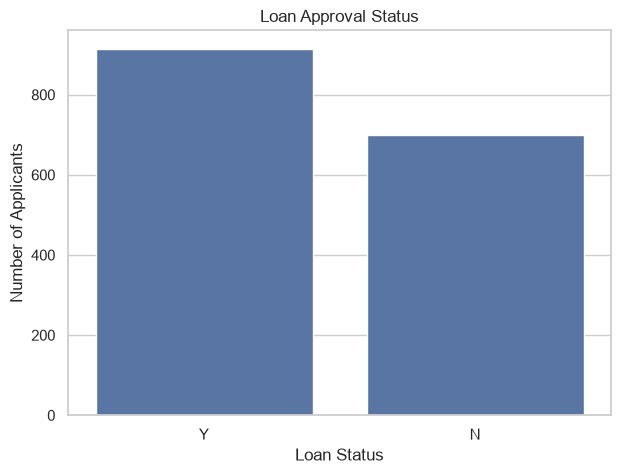

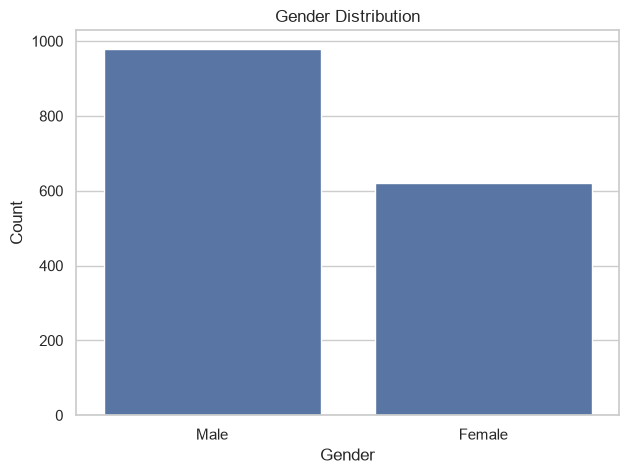

In [14]:
# ==================================================
# STEP 11: VISUALIZATION
# ==================================================
# 1. Loan Status Count
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

# 2. Gender Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

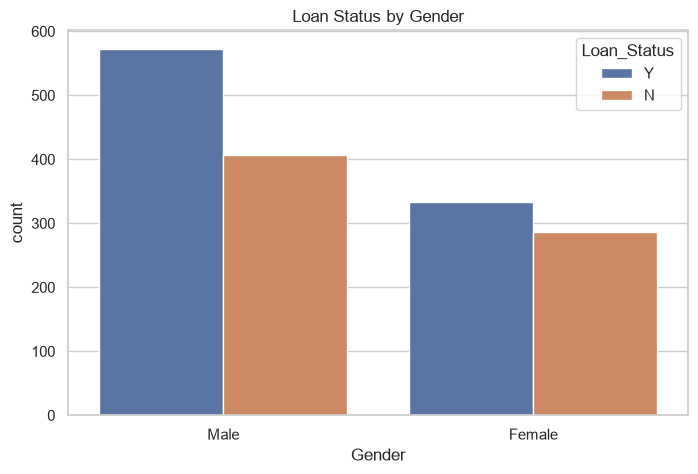

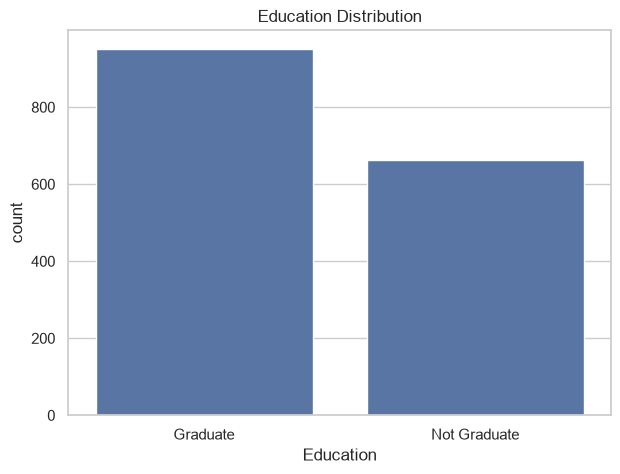

In [15]:
# 3. Loan Status by Gender

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Gender",
    hue="Loan_Status")
plt.title("Loan Status by Gender")
plt.show()

# 4. Education Distribution

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Education")
plt.title("Education Distribution")
plt.show()

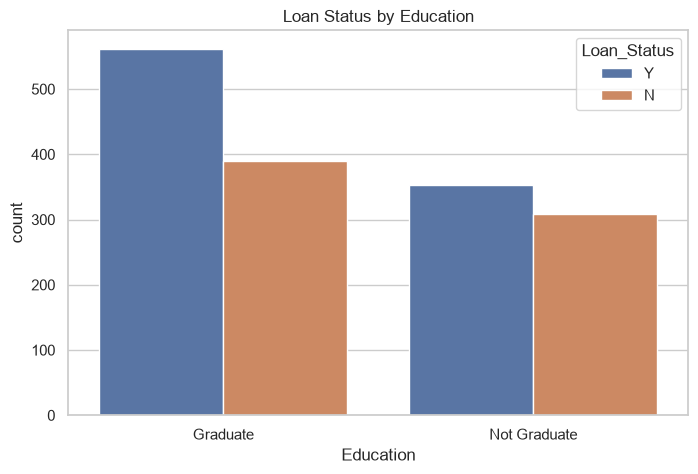

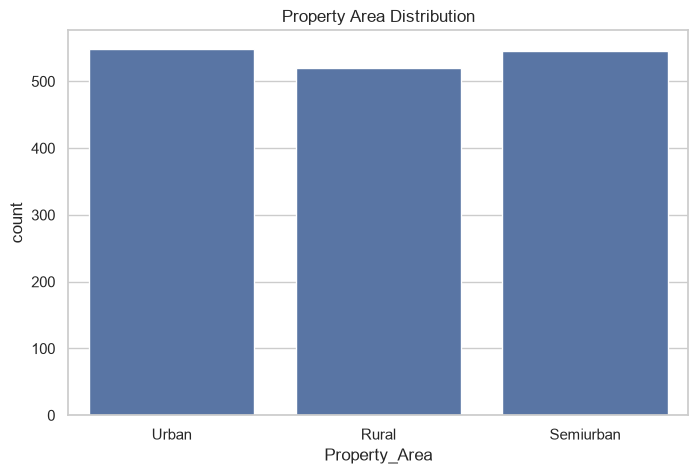

In [16]:
# 5. Loan Status by Education

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status")
plt.title("Loan Status by Education")
plt.show()

# 6. Property Area Distribution

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Property_Area")
plt.title("Property Area Distribution")
plt.show()

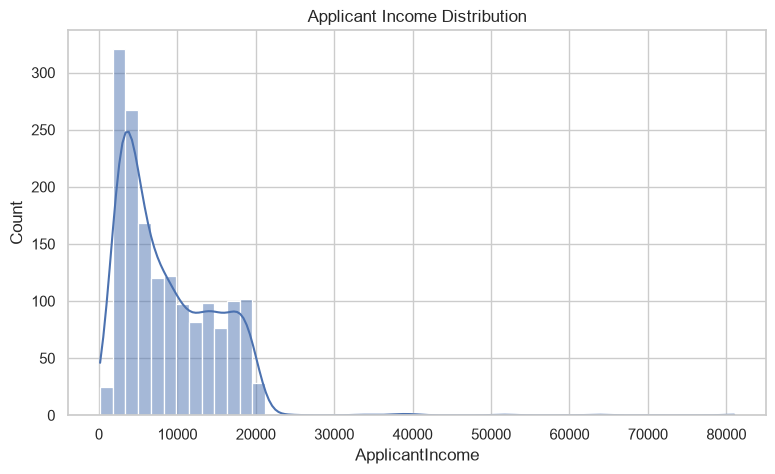

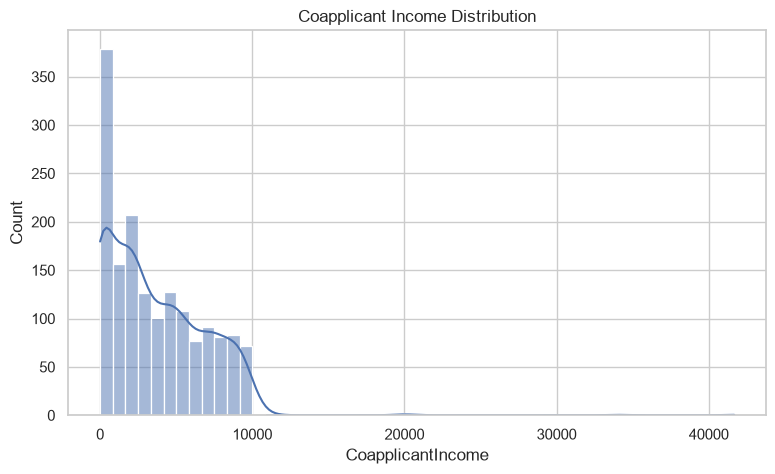

In [17]:
# 7. Applicant Income Distribution

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="ApplicantIncome",
    kde=True)
plt.title("Applicant Income Distribution")
plt.show()

# 8. Coapplicant Income Distribution

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="CoapplicantIncome",
    kde=True)
plt.title("Coapplicant Income Distribution")
plt.show()

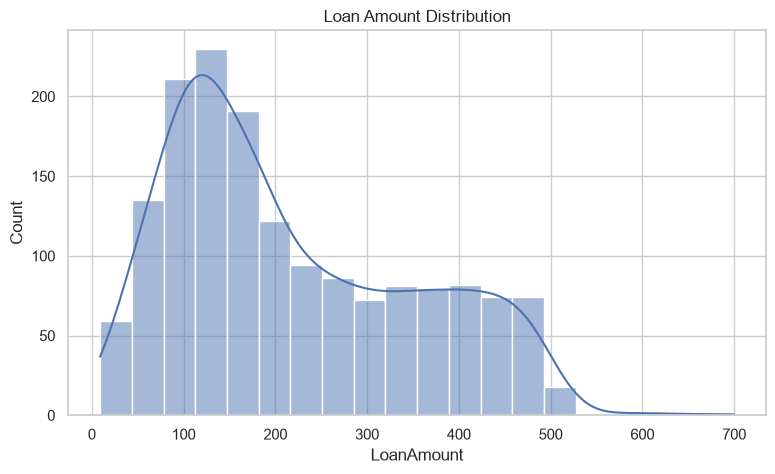

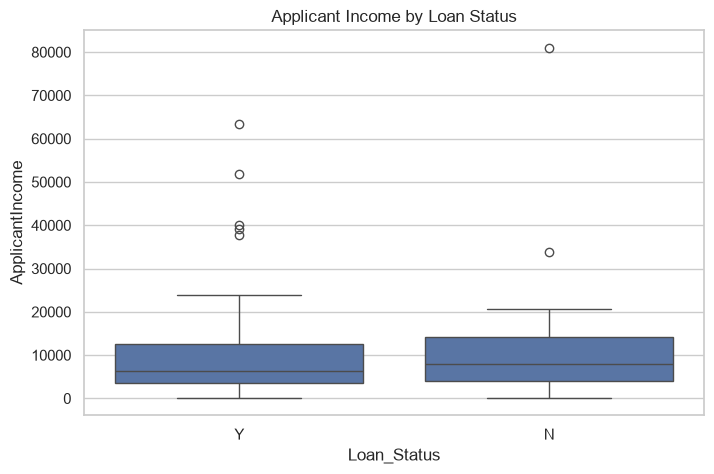

In [18]:
# 9. Loan Amount Distribution

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="LoanAmount",
    kde=True)
plt.title("Loan Amount Distribution")
plt.show()

# 10. Applicant Income by Loan Status

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Loan_Status",
    y="ApplicantIncome")
plt.title("Applicant Income by Loan Status")
plt.show()

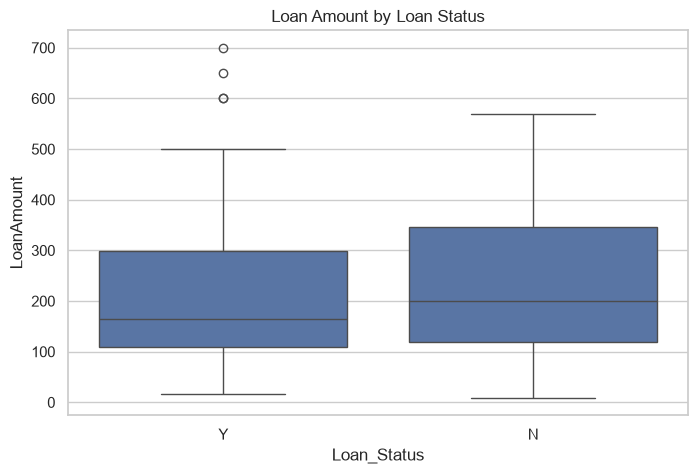

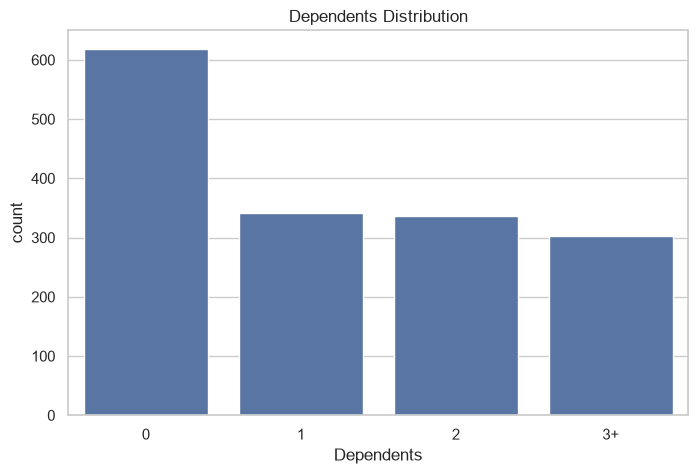

In [19]:
# 11. Loan Amount by Loan Status
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Loan_Status",
    y="LoanAmount")
plt.title("Loan Amount by Loan Status")
plt.show()

# 12. Dependents Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Dependents")
plt.title("Dependents Distribution")
plt.show()


Correlation Matrix:
                   ApplicantIncome  CoapplicantIncome  LoanAmount  \
ApplicantIncome           1.000000           0.167029    0.291225   
CoapplicantIncome         0.167029           1.000000    0.242683   
LoanAmount                0.291225           0.242683    1.000000   
Loan_Amount_Term         -0.210161          -0.258953   -0.226020   
Credit_History           -0.125381          -0.151693   -0.147051   
Total_Income              0.902471           0.575438    0.347596   

                   Loan_Amount_Term  Credit_History  Total_Income  
ApplicantIncome           -0.210161       -0.125381      0.902471  
CoapplicantIncome         -0.258953       -0.151693      0.575438  
LoanAmount                -0.226020       -0.147051      0.347596  
Loan_Amount_Term           1.000000        0.172390     -0.287462  
Credit_History             0.172390        1.000000     -0.170276  
Total_Income              -0.287462       -0.170276      1.000000  


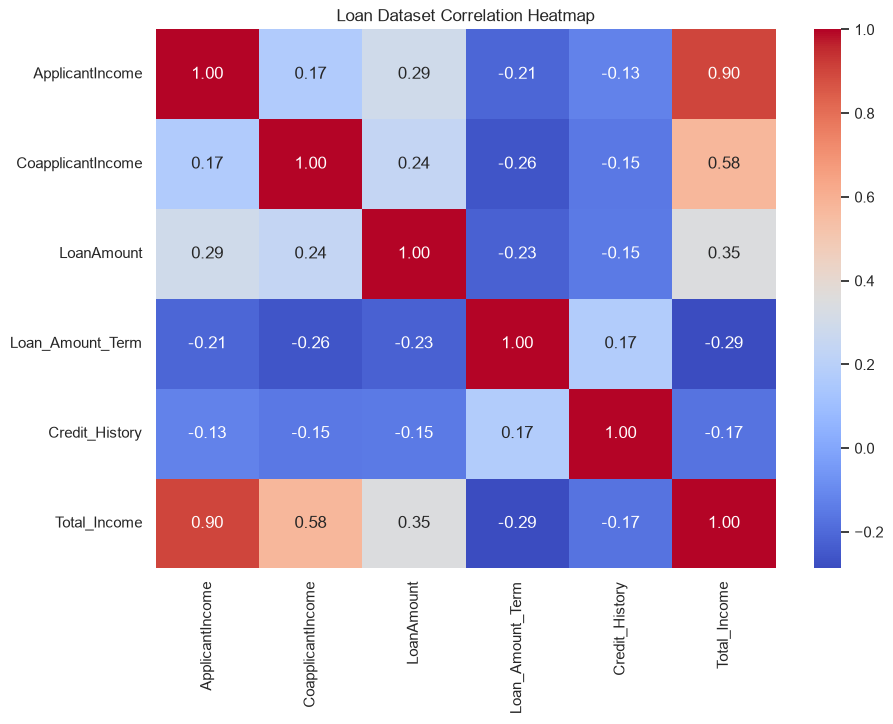

In [20]:
# ==================================================
# STEP 12: CORRELATION ANALYSIS
# ==================================================

numeric_data = df.select_dtypes(include=np.number)
correlation = numeric_data.corr()

print("\nCorrelation Matrix:")
print(correlation)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Loan Dataset Correlation Heatmap")
plt.show()

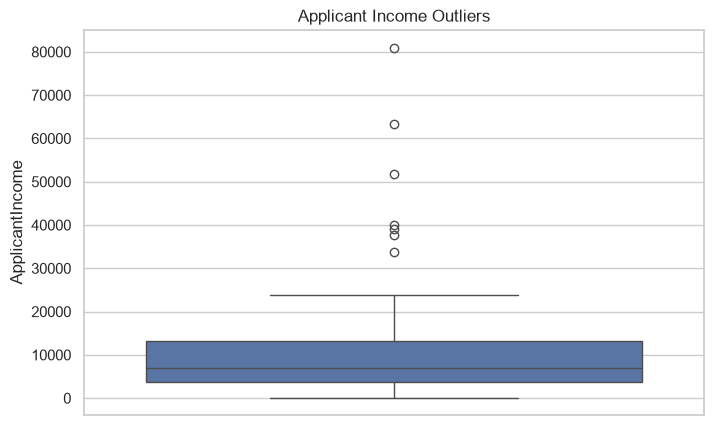

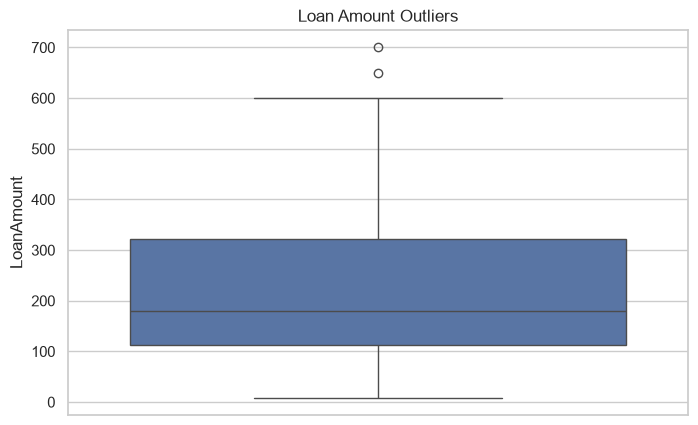

In [21]:
# ==================================================
# STEP 13: OUTLIER DETECTION
# ==================================================

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y="ApplicantIncome")
plt.title("Applicant Income Outliers")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y="LoanAmount")
plt.title("Loan Amount Outliers")
plt.show()

In [22]:
# ==================================================
# STEP 14: FINAL DATASET CHECK
# ==================================================

print("\nFinal Dataset Information:")
df.info()
print("\nFinal Dataset Shape:")
print(df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())
print("\nRemaining Duplicate Rows:")
print(df.duplicated().sum())


Final Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1614 non-null   float64
 9   Loan_Amount_Term   1614 non-null   float64
 10  Credit_History     1614 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
 13  Total_Income       1614 non-null   float64
dtypes: float64(5), int64(1), str(8)
memory usage: 233.9 KB

Final Dataset Shape:
(1614, 14)

Remaining Miss

In [23]:
# ==================================================
# STEP 15: SAVE CLEANED DATASET
# ==================================================

df.to_csv(
    "Loan_Eligibility_Cleaned.csv",
    index=False)

print("\nCleaned Dataset Saved Successfully!")
print("\nFile Name: Loan_Eligibility_Cleaned.csv")


Cleaned Dataset Saved Successfully!

File Name: Loan_Eligibility_Cleaned.csv


In [24]:
# ==================================================
# FINAL MESSAGE
# ==================================================

print("\n====================================")
print("LOAN ELIGIBILITY EDA COMPLETED")
print("====================================")


LOAN ELIGIBILITY EDA COMPLETED


In [25]:
data = pd.read_csv("hotel_booking.csv")
data

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,Transient,96.14,0,0,Check-Out,2017-09-06,Claudia Johnson,Claudia.J@yahoo.com,403-092-5582,************8647
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,Transient,225.43,0,2,Check-Out,2017-09-07,Wesley Aguilar,WAguilar@xfinity.com,238-763-0612,************4333
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,Transient,157.71,0,4,Check-Out,2017-09-07,Mary Morales,Mary_Morales@hotmail.com,395-518-4100,************1821
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,Transient,104.40,0,0,Check-Out,2017-09-07,Caroline Conley MD,MD_Caroline@comcast.net,531-528-1017,************7860


In [26]:
# ============================================================
# HOTEL BOOKING DATASET - COMPLETE EDA AND DATA CLEANING
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [27]:
# ============================================================
# STEP 2: LOAD DATASET
# ============================================================

df = pd.read_csv("hotel_booking.csv")

print("\nFirst 5 Rows:")
print(df.head())
print("\nLast 5 Rows:")
print(df.tail())


First 5 Rows:
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  customer_type  \
0                        0                     0       2  ...      Tr

In [28]:
# ============================================================
# STEP 3: BASIC DATASET INFORMATION
# ============================================================

print("\nDataset Shape:")
print(df.shape)

print("\nTotal Rows:")
print(df.shape[0])

print("\nTotal Columns:")
print(df.shape[1])


Dataset Shape:
(119390, 36)

Total Rows:
119390

Total Columns:
36


In [29]:
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nComplete Statistical Summary:")
print(df.describe(include="all"))


Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'name', 'email', 'phone-number', 'credit_card']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_ca

In [30]:
# ============================================================
# STEP 4: REMOVE PERSONAL INFORMATION
# ============================================================

# These columns contain personal contact information.
# They are not needed for hotel booking analysis.

personal_columns = [
    "name",
    "email",
    "phone-number",
    "credit_card"]

df.drop(
    columns=personal_columns,
    errors="ignore",
    inplace=True)

print("\nPersonal information columns removed.")
print("\nUpdated Dataset Shape:")
print(df.shape)


Personal information columns removed.

Updated Dataset Shape:
(119390, 32)


In [31]:
# ============================================================
# STEP 5: CHECK MISSING VALUES
# ============================================================

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df)) * 100)


Missing Values in Each Column:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                    

In [33]:
# ============================================================
# STEP 6: CHECK DUPLICATES
# ============================================================

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

# Remove duplicate rows

df.drop_duplicates(inplace=True)

print("\nShape After Removing Duplicates:")
print(df.shape)


Total Duplicate Rows:
31994

Shape After Removing Duplicates:
(87396, 32)


In [34]:
# ============================================================
# STEP 7: DATA CLEANING
# ============================================================
# Remove extra spaces from column names

df.columns = df.columns.str.strip()
# Replace question marks and blank spaces with NaN
df.replace(["?", " "], np.nan, inplace=True)

# Convert reservation date into datetime format
df["reservation_status_date"] = pd.to_datetime(
    df["reservation_status_date"],
    errors="coerce")

# Convert numeric columns into numeric data types
numeric_columns = [
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "agent",
    "company",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce")

# Fill missing numeric values using median
for col in numeric_columns:
    if col in df.columns and df[col].isnull().any():
        df[col] = df[col].fillna(
            df[col].median())

# Fill missing categorical values with Unknown
print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
numerical_columns = df.select_dtypes(include=['number']).columns
print(numerical_columns)
      
# Fill missing reservation dates with the mode date
if df["reservation_status_date"].isnull().any():
    mode_date = df["reservation_status_date"].mode()

    if not mode_date.empty:
        df["reservation_status_date"] = (
            df["reservation_status_date"].fillna(mode_date[0]))

print("\nData Cleaning Completed!")
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())
print("\nDataset Shape After Cleaning:")
print(df.shape)

Categorical Columns:
Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='str')

Numerical Columns:
Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='str')

Data Cleaning Completed!

Missing Values After Cleaning:
hotel                               0
is_canceled                         0
lead_time                           0
arrival_date_year                   0
arrival_date_month                  0
arrival_date_week_number            0
arrival_date_day_of_month           0
stays_in_weekend_nights 

In [35]:
# ============================================================
# STEP 8: CHECK DATA TYPES
# ============================================================

print("\nData Types:")
print(df.dtypes)
print("\nNumeric Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
numerical_columns = df.select_dtypes(include=['number']).columns
print(numerical_columns)


Data Types:
hotel                                        str
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                           str
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                         str
country                                      str
market_segment                               str
distribution_channel                         str
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                           str
assigne

In [36]:
# ============================================================
# STEP 9: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Hotel Type
print("\nHotel Type Distribution:")
print(df["hotel"].value_counts())

# Cancellation Status
print("\nCancellation Distribution:")
print(df["is_canceled"].value_counts())

# Customer Type
print("\nCustomer Type Distribution:")
print(df["customer_type"].value_counts())

# Market Segment
print("\nMarket Segment Distribution:")
print(df["market_segment"].value_counts())

# Distribution Channel
print("\nDistribution Channel:")
print(df["distribution_channel"].value_counts())

# Meal Type
print("\nMeal Type Distribution:")
print(df["meal"].value_counts())

# Country
print("\nTop 10 Countries:")
print(df["country"].value_counts().head(10))

# Reservation Status
print("\nReservation Status:")
print(df["reservation_status"].value_counts())

# Deposit Type
print("\nDeposit Type:")
print(df["deposit_type"].value_counts())


Hotel Type Distribution:
hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

Cancellation Distribution:
is_canceled
0    63371
1    24025
Name: count, dtype: int64

Customer Type Distribution:
customer_type
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64

Market Segment Distribution:
market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

Distribution Channel:
distribution_channel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

Meal Type Distribution:
meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64

Top 10 Countries:
country
PRT    27453
GBR    10433
FRA     8837
ESP 

In [37]:
# ============================================================
# STEP 10: NUMERICAL ANALYSIS
# ============================================================

print("\nAverage Lead Time:")
print(df["lead_time"].mean())

print("\nAverage Daily Rate:")
print(df["adr"].mean())

print("\nMaximum Daily Rate:")
print(df["adr"].max())

print("\nMinimum Daily Rate:")
print(df["adr"].min())

print("\nAverage Adults:")
print(df["adults"].mean())

print("\nAverage Children:")
print(df["children"].mean())

print("\nAverage Weekend Nights:")
print(df["stays_in_weekend_nights"].mean())

print("\nAverage Week Nights:")
print(df["stays_in_week_nights"].mean())

print("\nAverage Waiting List Days:")
print(df["days_in_waiting_list"].mean())

print("\nTotal Special Requests:")
print(df["total_of_special_requests"].sum())


Average Lead Time:
79.89136802599661

Average Daily Rate:
106.33724644148474

Maximum Daily Rate:
5400.0

Minimum Daily Rate:
-6.38

Average Adults:
1.8757952309030161

Average Children:
0.13863334706393884

Average Weekend Nights:
1.005263398782553

Average Week Nights:
2.6253947549086916

Average Waiting List Days:
0.7495651974918761

Total Special Requests:
61052


In [38]:
# ============================================================
# STEP 11: GROUP ANALYSIS
# ============================================================

# Cancellation by Hotel Type
print("\nCancellation by Hotel Type:")
print(
    pd.crosstab(
        df["hotel"],
        df["is_canceled"]))

# Cancellation by Customer Type
print("\nCancellation by Customer Type:")
print(
    pd.crosstab(
        df["customer_type"],
        df["is_canceled"]))

# Cancellation by Market Segment
print("\nCancellation by Market Segment:")
print(
    pd.crosstab(
        df["market_segment"],
        df["is_canceled"]))

# Cancellation by Deposit Type
print("\nCancellation by Deposit Type:")
print(
    pd.crosstab(
        df["deposit_type"],
        df["is_canceled"]))

# Average Daily Rate by Hotel
print("\nAverage Daily Rate by Hotel:")
print(
    df.groupby("hotel")["adr"].mean())

# Average Lead Time by Hotel
print("\nAverage Lead Time by Hotel:")
print(
    df.groupby("hotel")["lead_time"].mean())

# Bookings by Hotel Type
print("\nBookings by Hotel Type:")
print(
    df.groupby("hotel").size())

# Average Daily Rate by Customer Type
print("\nAverage Daily Rate by Customer Type:")
print(
    df.groupby("customer_type")["adr"].mean())


Cancellation by Hotel Type:
is_canceled       0      1
hotel                     
City Hotel    37379  16049
Resort Hotel  25992   7976

Cancellation by Customer Type:
is_canceled          0      1
customer_type                
Contract          2627    512
Group              490     54
Transient        50314  21672
Transient-Party   9940   1787

Cancellation by Market Segment:
is_canceled         0      1
market_segment              
Aviation          182     45
Complementary     614     88
Corporate        3702    510
Direct          10067   1737
Groups           3607   1335
Offline TA/TO   11826   2063
Online TA       33373  18245
Undefined           0      2

Cancellation by Deposit Type:
is_canceled       0      1
deposit_type              
No Deposit    63235  23016
Non Refund       55    983
Refundable       81     26

Average Daily Rate by Hotel:
hotel
City Hotel      110.985944
Resort Hotel     99.025346
Name: adr, dtype: float64

Average Lead Time by Hotel:
hotel
City Hotel 

In [39]:
# ============================================================
# STEP 12: CREATE NEW COLUMNS
# ============================================================

# Total nights spent by guests
df["total_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"])

print("\nTotal Nights:")
print(df["total_nights"].head())

# Total guests
df["total_guests"] = (
    df["adults"]
    + df["children"]
    + df["babies"])

print("\nTotal Guests:")
print(df["total_guests"].head())

# Check new columns
print("\nDataset with New Columns:")
print(
    df[
        [
            "hotel",
            "total_nights",
            "total_guests"]
        ].head())


Total Nights:
0    0
1    0
2    1
3    1
4    2
Name: total_nights, dtype: int64

Total Guests:
0    2.0
1    2.0
2    1.0
3    1.0
4    2.0
Name: total_guests, dtype: float64

Dataset with New Columns:
          hotel  total_nights  total_guests
0  Resort Hotel             0           2.0
1  Resort Hotel             0           2.0
2  Resort Hotel             1           1.0
3  Resort Hotel             1           1.0
4  Resort Hotel             2           2.0


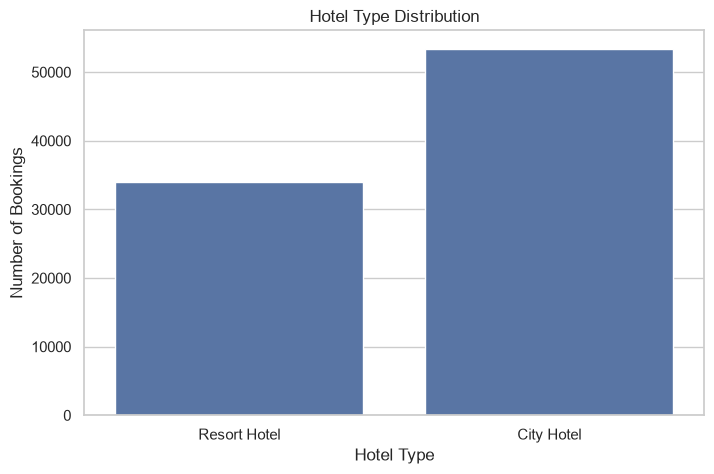

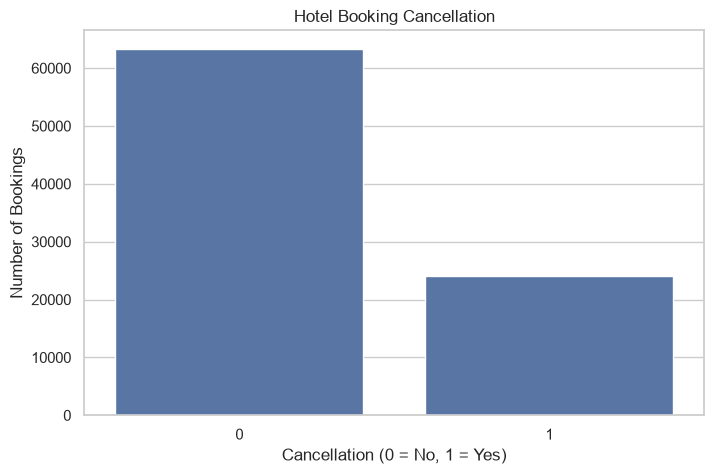

In [40]:
# ============================================================
# STEP 13: VISUALIZATION
# ============================================================

# 1. Hotel Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="hotel")

plt.title("Hotel Type Distribution")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.show()

# 2. Booking Cancellation
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="is_canceled")

plt.title("Hotel Booking Cancellation")
plt.xlabel("Cancellation (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.show()

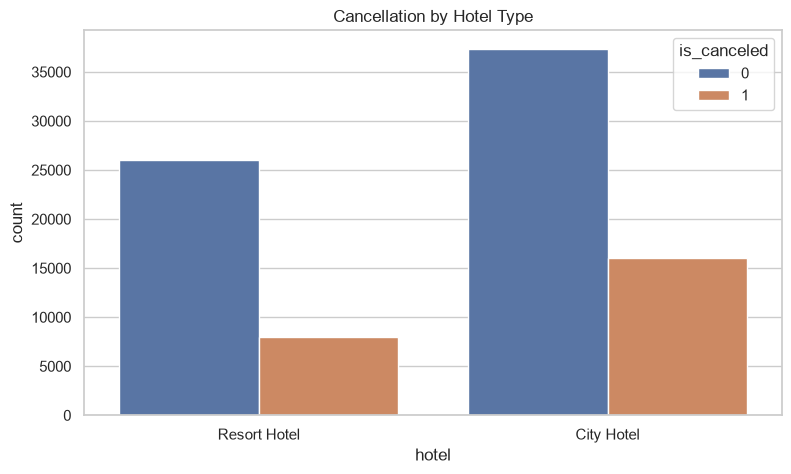

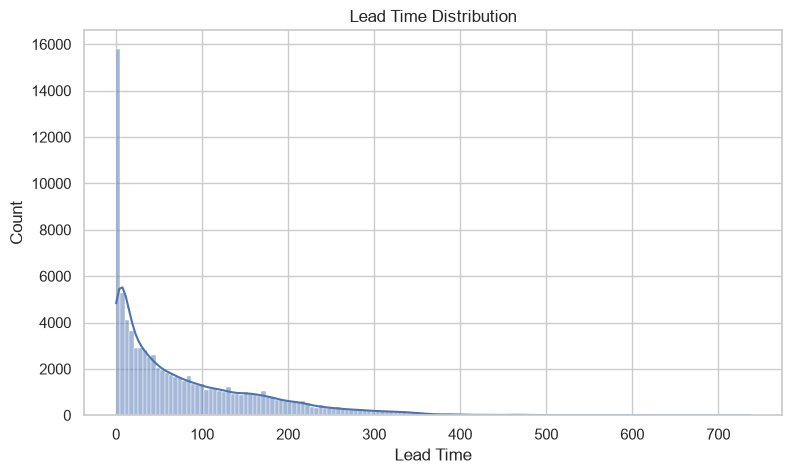

In [41]:
# 3. Cancellation by Hotel Type
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="hotel",
    hue="is_canceled")

plt.title("Cancellation by Hotel Type")
plt.show()

# 4. Lead Time Distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="lead_time",
    kde=True)

plt.title("Lead Time Distribution")
plt.xlabel("Lead Time")
plt.show()

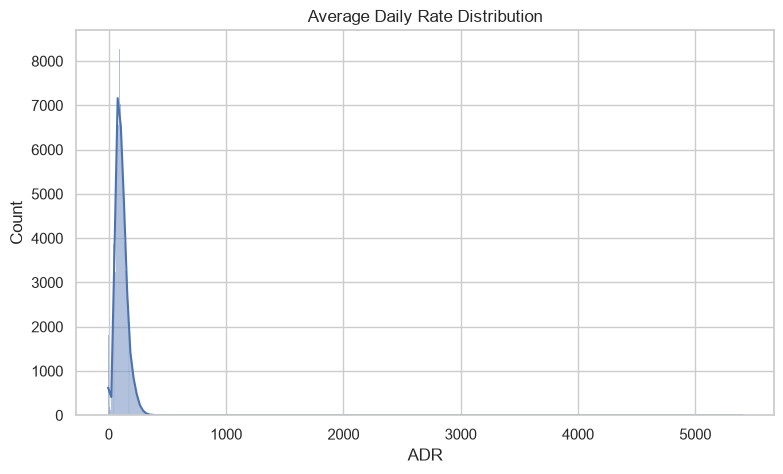

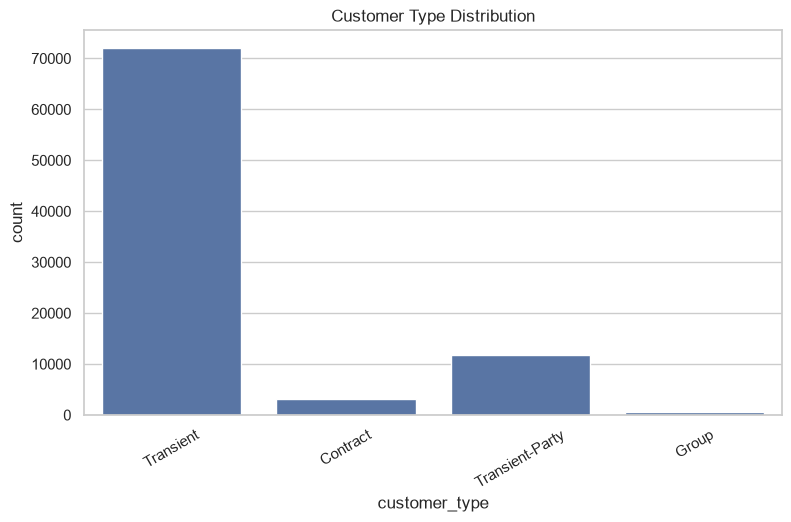

In [42]:
# 5. Average Daily Rate Distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="adr",
    kde=True)

plt.title("Average Daily Rate Distribution")
plt.xlabel("ADR")
plt.show()

# 6. Customer Type Distribution
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="customer_type")

plt.title("Customer Type Distribution")
plt.xticks(rotation=30)
plt.show()

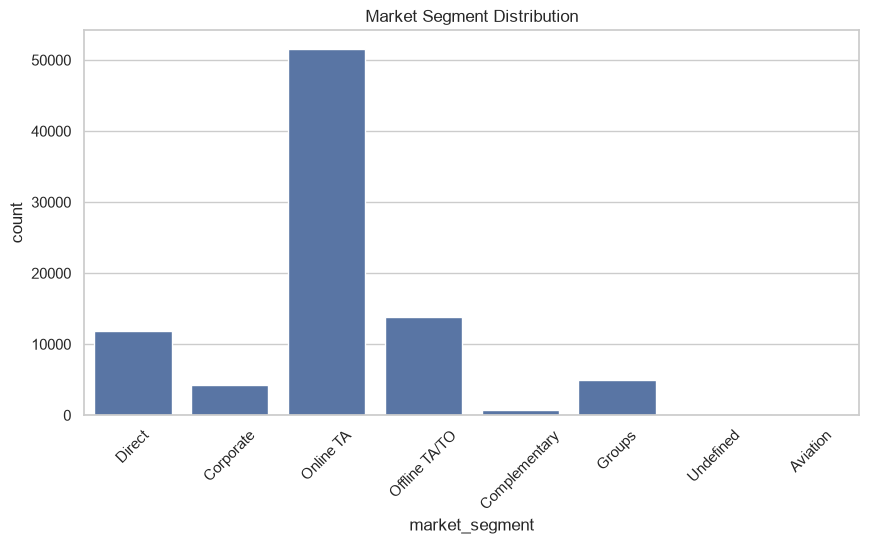

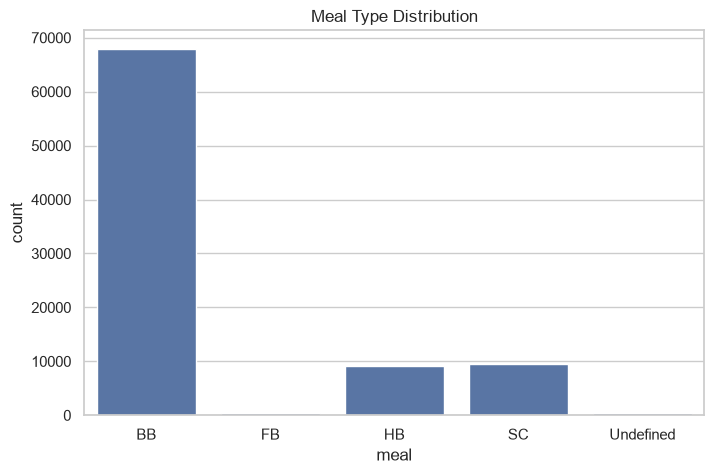

In [43]:
# 7. Market Segment Distribution
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="market_segment")

plt.title("Market Segment Distribution")
plt.xticks(rotation=45)
plt.show()

# 8. Meal Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="meal")

plt.title("Meal Type Distribution")
plt.show()


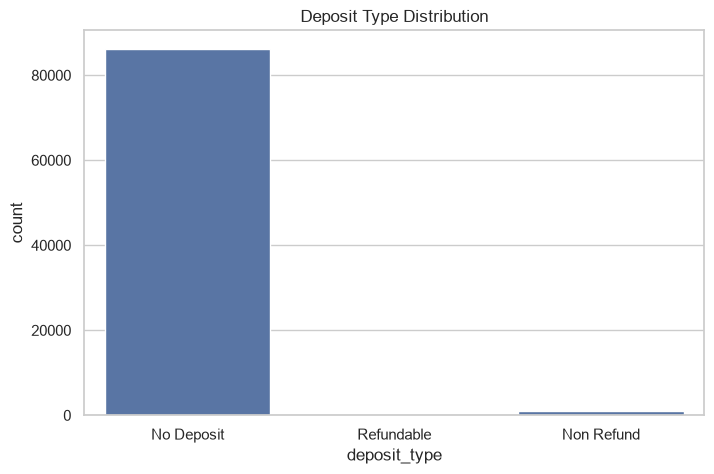

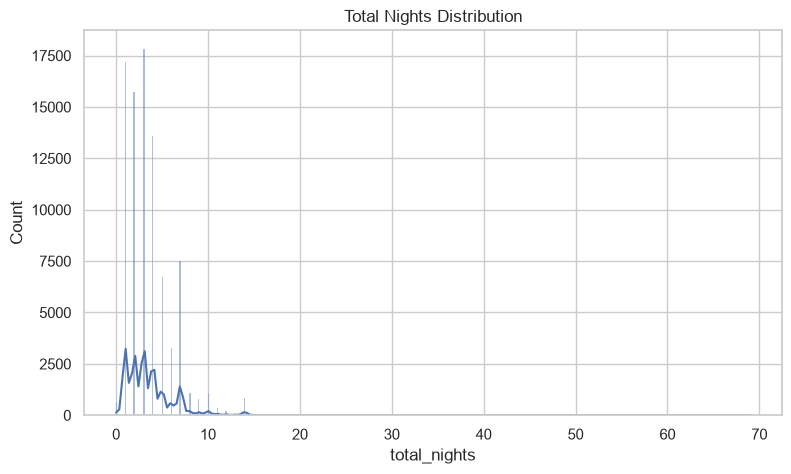

In [44]:
# 9. Deposit Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="deposit_type")

plt.title("Deposit Type Distribution")
plt.show()

# 10. Total Nights Distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="total_nights",
    kde=True)

plt.title("Total Nights Distribution")
plt.show()

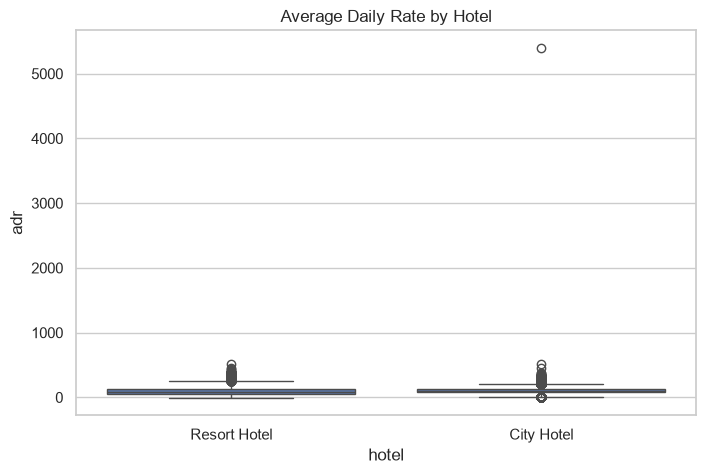

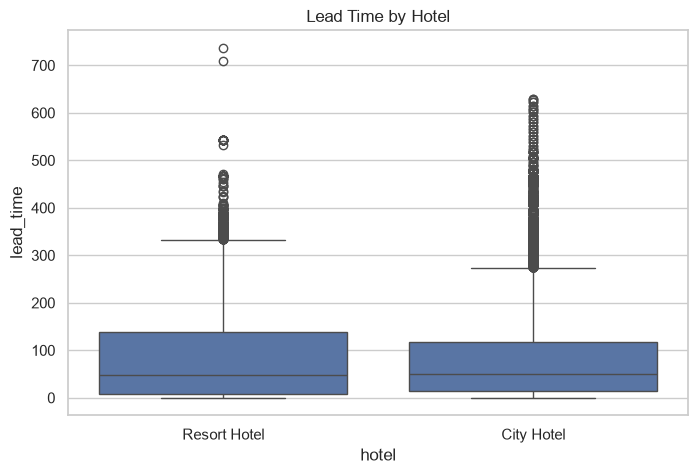

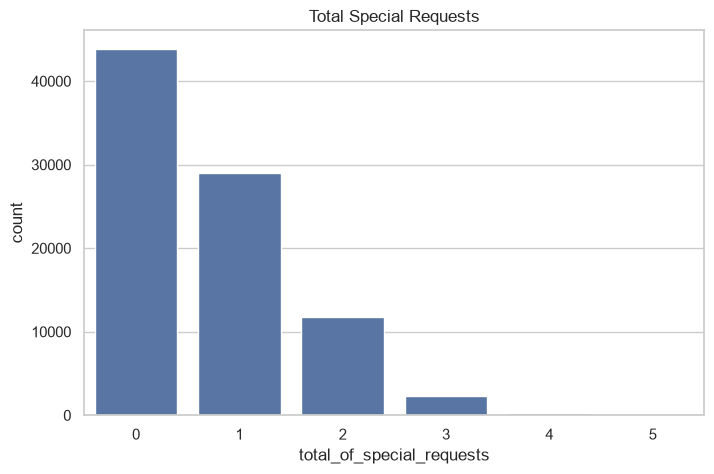

In [45]:
# 11. Average Daily Rate by Hotel
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="hotel",
    y="adr")

plt.title("Average Daily Rate by Hotel")
plt.show()

# 12. Lead Time by Hotel
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="hotel",
    y="lead_time")

plt.title("Lead Time by Hotel")
plt.show()

# 13. Special Requests
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="total_of_special_requests")

plt.title("Total Special Requests")
plt.show()

In [46]:
# ============================================================
# STEP 14: CORRELATION ANALYSIS
# ============================================================

numeric_data = df.select_dtypes(
    include=np.number)

correlation = numeric_data.corr()
print("\nCorrelation Matrix:")
print(correlation)


Correlation Matrix:
                                is_canceled  lead_time  arrival_date_year  \
is_canceled                        1.000000   0.184806           0.088030   
lead_time                          0.184806   1.000000           0.139135   
arrival_date_year                  0.088030   0.139135           1.000000   
arrival_date_week_number           0.001443   0.101150          -0.514228   
arrival_date_day_of_month          0.005328   0.009866          -0.010023   
stays_in_weekend_nights            0.060191   0.235145           0.005144   
stays_in_week_nights               0.082928   0.310129           0.003645   
adults                             0.081816   0.140493           0.038619   
children                           0.067369   0.028650           0.041158   
babies                            -0.020543  -0.003614          -0.023334   
is_repeated_guest                 -0.089643  -0.147003           0.024343   
previous_cancellations             0.051468   0.005375 

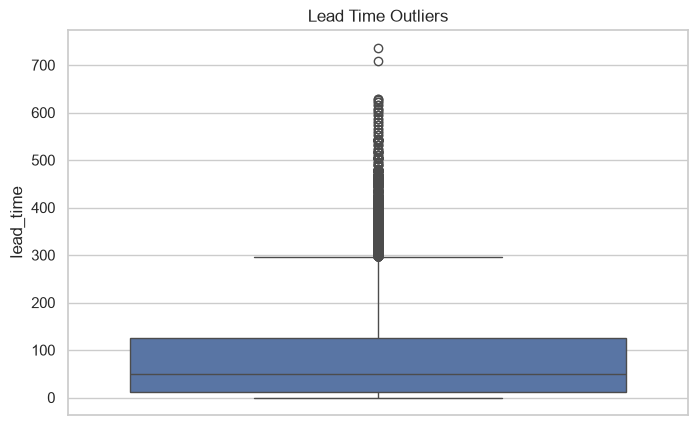

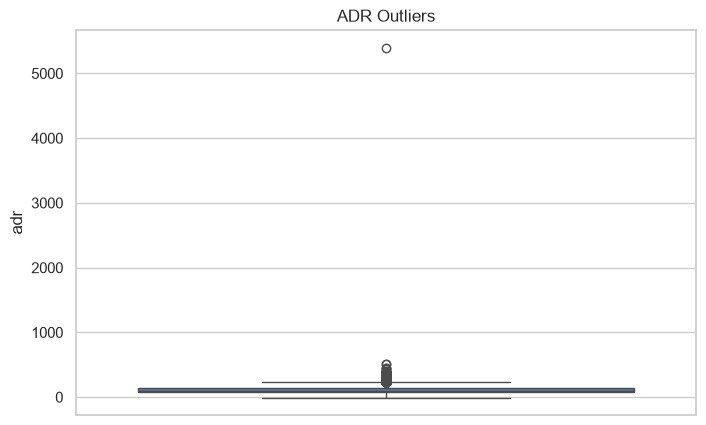

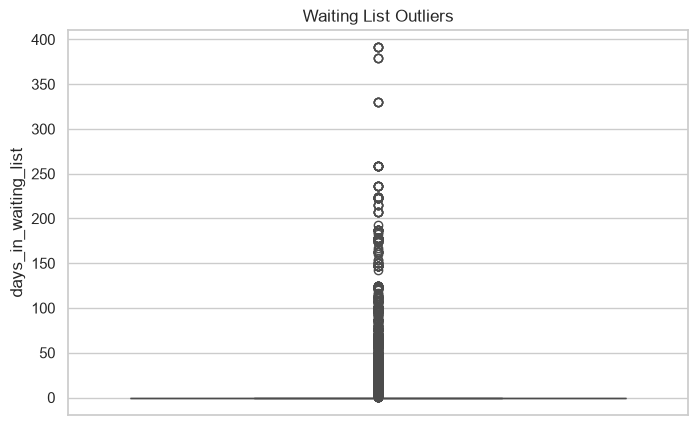

In [48]:
# ============================================================
# STEP 15: OUTLIER DETECTION
# ============================================================

# Lead Time Outliers
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    y="lead_time")

plt.title("Lead Time Outliers")
plt.show()

# ADR Outliers
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    y="adr")

plt.title("ADR Outliers")
plt.show()

# Waiting List Outliers
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    y="days_in_waiting_list")

plt.title("Waiting List Outliers")
plt.show()

In [49]:
# ============================================================
# STEP 16: FINAL DATASET CHECK
# ============================================================

print("\nFinal Dataset Information:")
df.info()

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())


Final Dataset Information:
<class 'pandas.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87396 non-null  str           
 1   is_canceled                     87396 non-null  int64         
 2   lead_time                       87396 non-null  int64         
 3   arrival_date_year               87396 non-null  int64         
 4   arrival_date_month              87396 non-null  str           
 5   arrival_date_week_number        87396 non-null  int64         
 6   arrival_date_day_of_month       87396 non-null  int64         
 7   stays_in_weekend_nights         87396 non-null  int64         
 8   stays_in_week_nights            87396 non-null  int64         
 9   adults                          87396 non-null  int64         
 10  children                        87396 non-null  float64  

In [50]:
print("\nRemaining Duplicate Rows:")
print(df.duplicated().sum())

print("\nFinal First 5 Rows:")
print(df.head())


Remaining Duplicate Rows:
0

Final First 5 Rows:
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  company  \
0                        0              

In [51]:
# ============================================================
# STEP 17: SAVE CLEANED DATASET
# ============================================================

df.to_csv(
    "Hotel_Booking_Cleaned.csv",
    index=False)

print("\nCleaned Dataset Saved Successfully!")
print("File Name: Hotel_Booking_Cleaned.csv")


Cleaned Dataset Saved Successfully!
File Name: Hotel_Booking_Cleaned.csv


In [52]:
# ============================================================
# FINAL MESSAGE
# ============================================================

print("\n======================================")
print("HOTEL BOOKING EDA COMPLETED")
print("======================================")


HOTEL BOOKING EDA COMPLETED


In [53]:
data = pd.read_csv("adult.csv")
data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [54]:
# =====================================================
# 1. IMPORT LIBRARIES
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
# =====================================================
# 2. LOAD DATASET
# =====================================================
df = pd.read_csv("adult.csv")

print("Dataset loaded successfully!")
print("First 5 rows:")
print(df.head())

Dataset loaded successfully!
First 5 rows:
   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0

In [56]:
# =====================================================
# 3. BASIC DATASET INFORMATION
# =====================================================
print("\nDataset Shape:")
print(df.shape)

print("\nDataset Columns:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())


Dataset Shape:
(48842, 15)

Dataset Columns:
Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  cap

In [57]:
# =====================================================
# 4. CHECK MISSING VALUES
# =====================================================
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values Before Cleaning:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Total Missing Values:
0


In [58]:
# =====================================================
# 5. CHECK DUPLICATE VALUES
# =====================================================
print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())


Total Duplicate Rows:
52


In [59]:
# =====================================================
# 6. CHECK UNIQUE VALUES
# =====================================================

print("\nUnique Values in Each Column:")
for column in df.columns:
    print(column, ":", df[column].nunique())


Unique Values in Each Column:
age : 74
workclass : 9
fnlwgt : 28523
education : 16
educational-num : 16
marital-status : 7
occupation : 15
relationship : 6
race : 5
gender : 2
capital-gain : 123
capital-loss : 99
hours-per-week : 96
native-country : 42
income : 2


In [60]:
# =====================================================
# 7. CHECK DATA TYPES
# =====================================================

print("\nData Types:")
print(df.dtypes)


Data Types:
age                int64
workclass            str
fnlwgt             int64
education            str
educational-num    int64
marital-status       str
occupation           str
relationship         str
race                 str
gender               str
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country       str
income               str
dtype: object


In [61]:

# =====================================================
# 8. DATA CLEANING
# =====================================================

# Make a copy of original dataset
df_clean = df.copy()

# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove extra spaces from text values
for column in df_clean.select_dtypes(include=["object", "str"]).columns:
    df_clean[column] = df_clean[column].str.strip()

# Replace ? and empty strings with NaN
df_clean.replace(["?", ""], np.nan, inplace=True)

print("\nMissing Values After Replacing ?:")
print(df_clean.isnull().sum())


Missing Values After Replacing ?:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


In [62]:
# =====================================================
# 9. REMOVE DUPLICATES
# =====================================================
before_duplicates = df_clean.shape[0]
df_clean.drop_duplicates(inplace=True)
after_duplicates = df_clean.shape[0]

print("\nDuplicate Rows Removed:")
print(before_duplicates - after_duplicates)

print("Dataset Shape After Removing Duplicates:")
print(df_clean.shape)


Duplicate Rows Removed:
52
Dataset Shape After Removing Duplicates:
(48790, 15)


In [63]:
# =====================================================
# 10. CONVERT NUMERIC COLUMNS
# =====================================================
numeric_columns = [
    "age",
    "fnlwgt",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column], errors="coerce")
print("\nNumeric Columns Converted Successfully!")


Numeric Columns Converted Successfully!


In [64]:
# =====================================================
# 11. HANDLE MISSING VALUES
# =====================================================
# Fill numeric missing values with median
for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median())
    
# Select categorical columns
categorical_columns = df_clean.select_dtypes(
    include=["object", "str"]).columns

# Fill categorical missing values with Unknown
for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

# Display missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

# Display total missing values
print("\nTotal Missing Values After Cleaning:")
print(df_clean.isnull().sum().sum())


Missing Values After Cleaning:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Total Missing Values After Cleaning:
0


In [65]:
# =====================================================
# 12. FINAL DATASET INFORMATION
# =====================================================

print("\nCleaned Dataset Shape:")
print(df_clean.shape)

print("\nCleaned Dataset Information:")
df_clean.info()

print("\nFirst 5 Cleaned Rows:")
print(df_clean.head())


Cleaned Dataset Shape:
(48790, 15)

Cleaned Dataset Information:
<class 'pandas.DataFrame'>
Index: 48790 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48790 non-null  int64
 1   workclass        48790 non-null  str  
 2   fnlwgt           48790 non-null  int64
 3   education        48790 non-null  str  
 4   educational-num  48790 non-null  int64
 5   marital-status   48790 non-null  str  
 6   occupation       48790 non-null  str  
 7   relationship     48790 non-null  str  
 8   race             48790 non-null  str  
 9   gender           48790 non-null  str  
 10  capital-gain     48790 non-null  int64
 11  capital-loss     48790 non-null  int64
 12  hours-per-week   48790 non-null  int64
 13  native-country   48790 non-null  str  
 14  income           48790 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.7 MB

First 5 Cleaned Rows:
   age  workclass  fnlwg

In [66]:
# =====================================================
# 13. EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================

# Check income distribution
print("\nIncome Distribution:")
print(df_clean["income"].value_counts())

print("\nIncome Percentage:")
print(df_clean["income"].value_counts(normalize=True) * 100)


Income Distribution:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Income Percentage:
income
<=50K    76.058619
>50K     23.941381
Name: proportion, dtype: float64


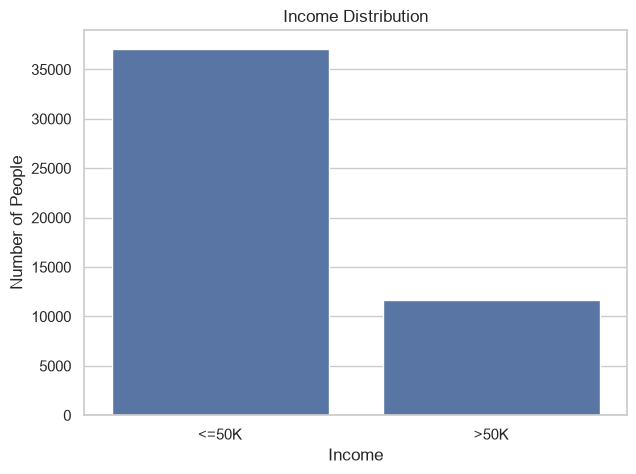

In [67]:
# =====================================================
# 14. INCOME COUNT PLOT
# =====================================================
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="income",
    order=df_clean["income"].value_counts().index)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")
plt.show()

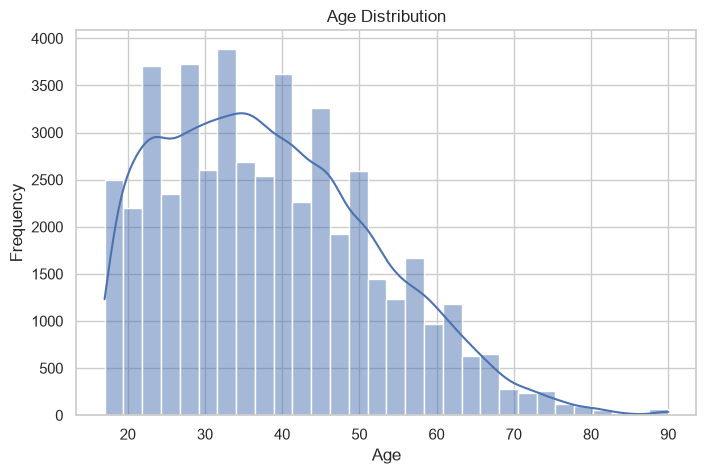

In [68]:
# =====================================================
# 15. AGE DISTRIBUTION
# =====================================================
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=30,
    kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

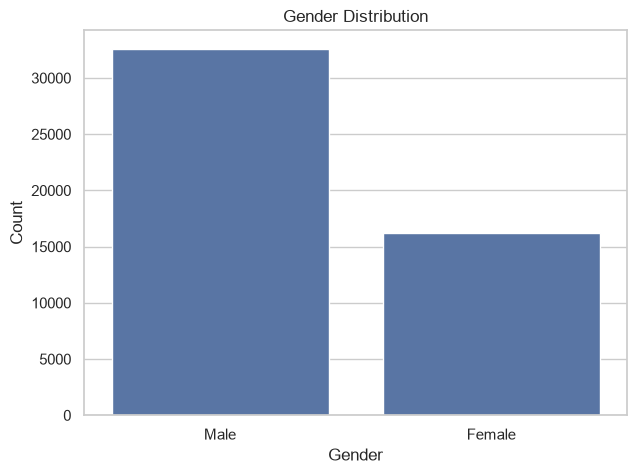

In [69]:
# =====================================================
# 16. GENDER DISTRIBUTION
# =====================================================
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df_clean,
    x="gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

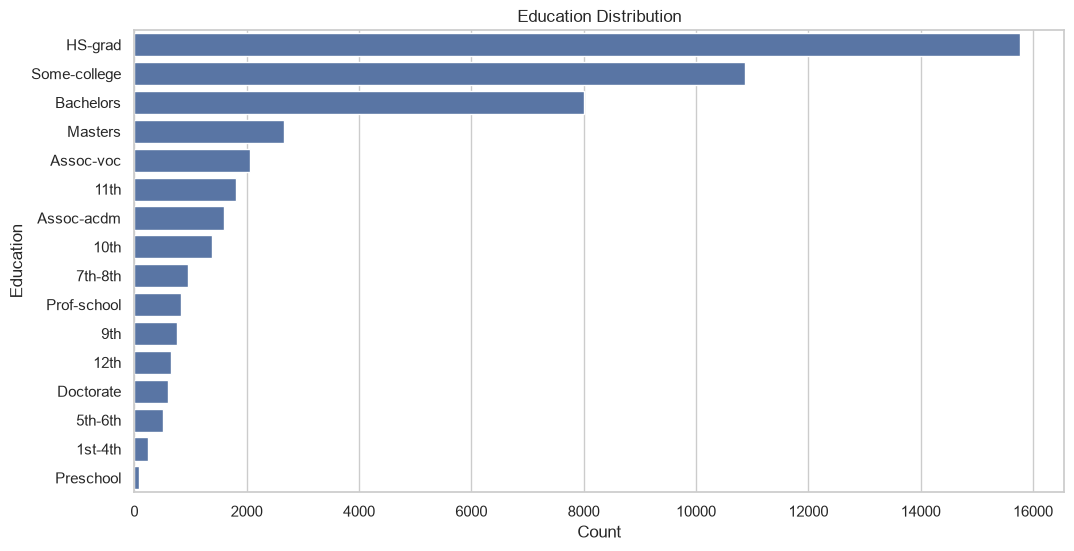

In [70]:
# =====================================================
# 17. EDUCATION DISTRIBUTION
# =====================================================
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    y="education",
    order=df_clean["education"].value_counts().index)

plt.title("Education Distribution")
plt.xlabel("Count")
plt.ylabel("Education")
plt.show()

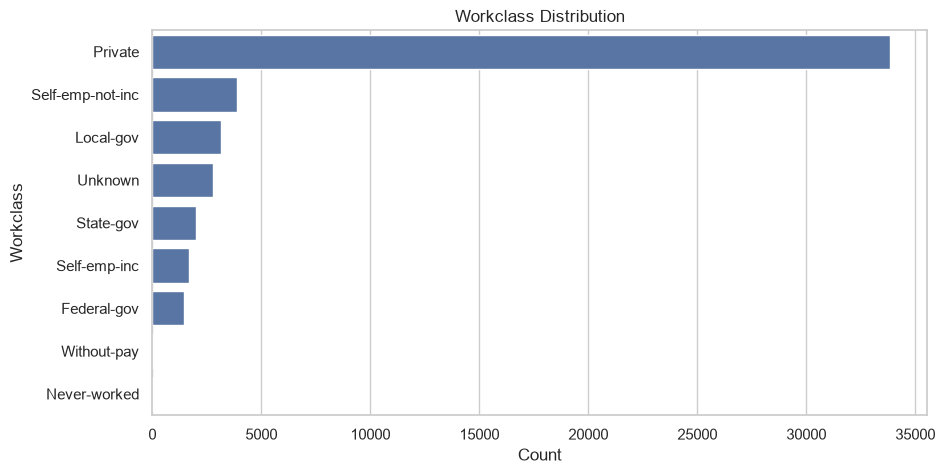

In [71]:
# =====================================================
# 18. WORKCLASS DISTRIBUTION
# =====================================================
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_clean,
    y="workclass",
    order=df_clean["workclass"].value_counts().index)

plt.title("Workclass Distribution")
plt.xlabel("Count")
plt.ylabel("Workclass")
plt.show()

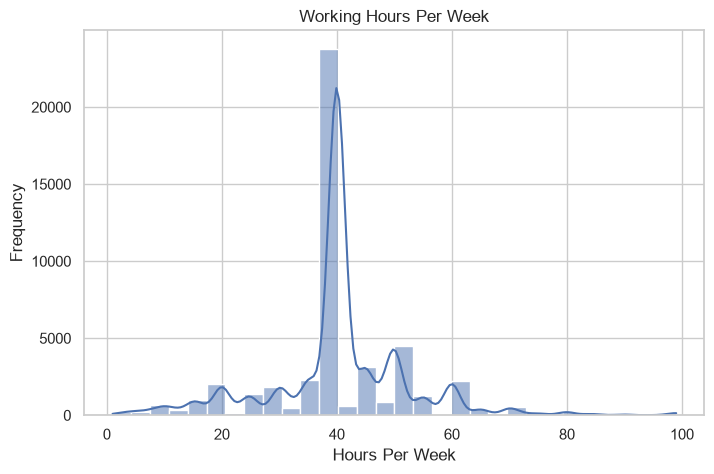

In [72]:
# =====================================================
# 19. HOURS PER WEEK DISTRIBUTION
# =====================================================
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="hours-per-week",
    bins=30,
    kde=True)

plt.title("Working Hours Per Week")
plt.xlabel("Hours Per Week")
plt.ylabel("Frequency")
plt.show()

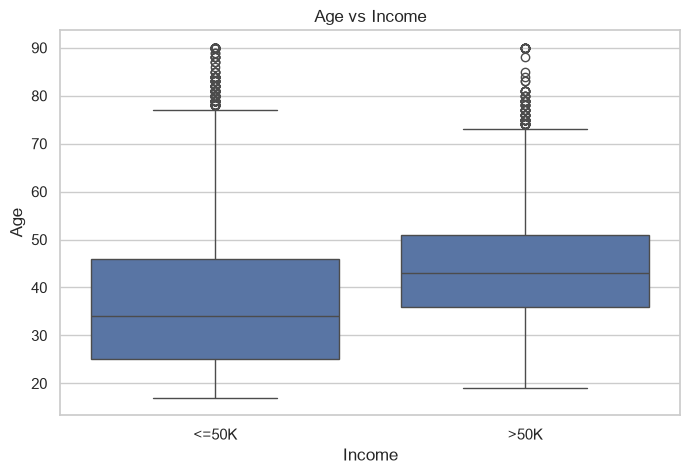

In [73]:
# =====================================================
# 20. AGE VS INCOME
# =====================================================
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="income",
    y="age")

plt.title("Age vs Income")
plt.xlabel("Income")
plt.ylabel("Age")
plt.show()

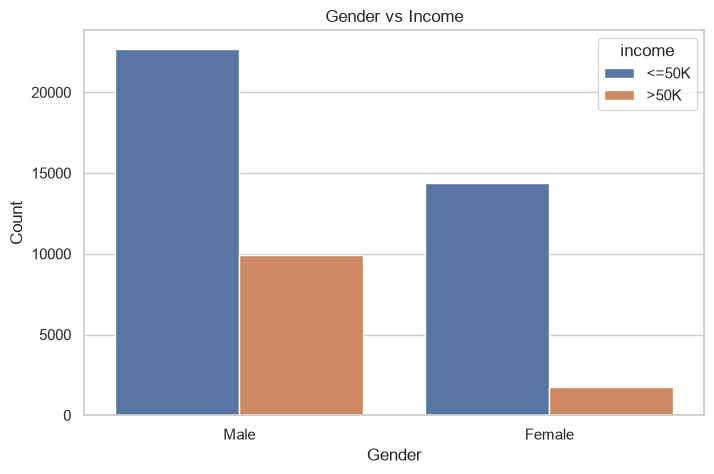

In [74]:
# =====================================================
# 21. GENDER VS INCOME
# =====================================================
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="gender",
    hue="income")

plt.title("Gender vs Income")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

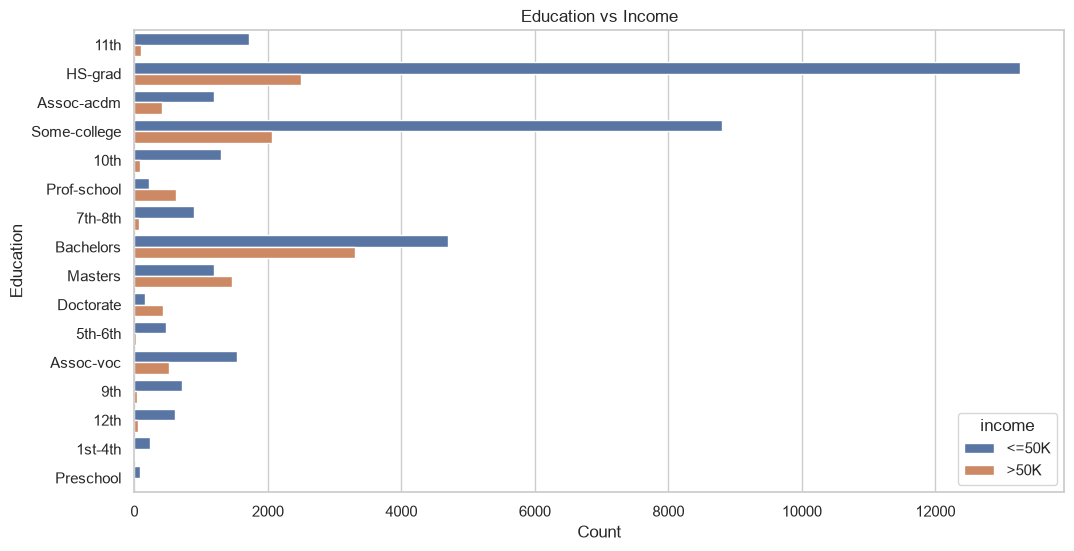

In [75]:
# =====================================================
# 22. EDUCATION VS INCOME
# =====================================================
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    y="education",
    hue="income")

plt.title("Education vs Income")
plt.xlabel("Count")
plt.ylabel("Education")
plt.show()

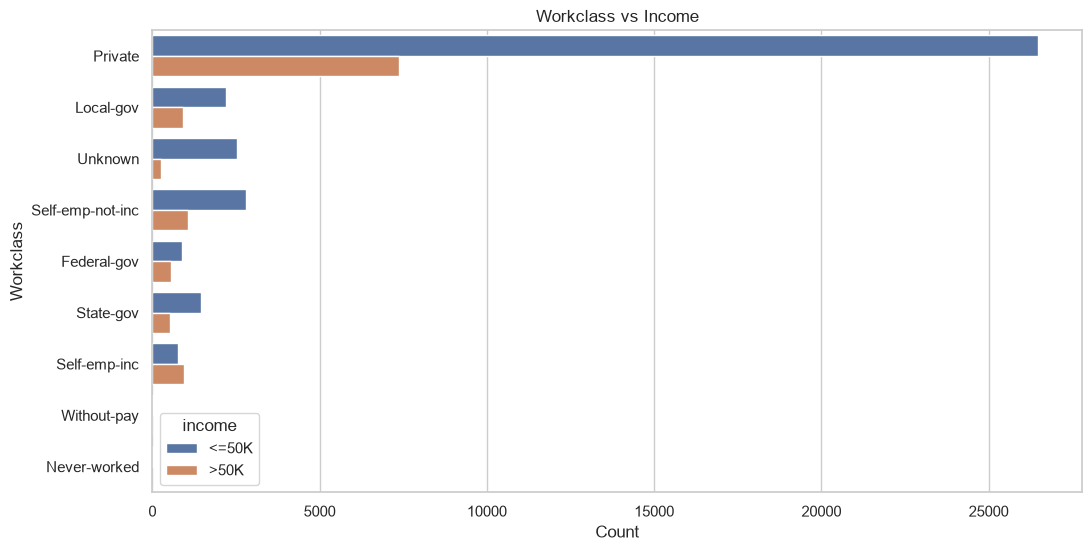

In [76]:
# =====================================================
# 23. WORKCLASS VS INCOME
# =====================================================
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_clean,
    y="workclass",
    hue="income")

plt.title("Workclass vs Income")
plt.xlabel("Count")
plt.ylabel("Workclass")
plt.show()

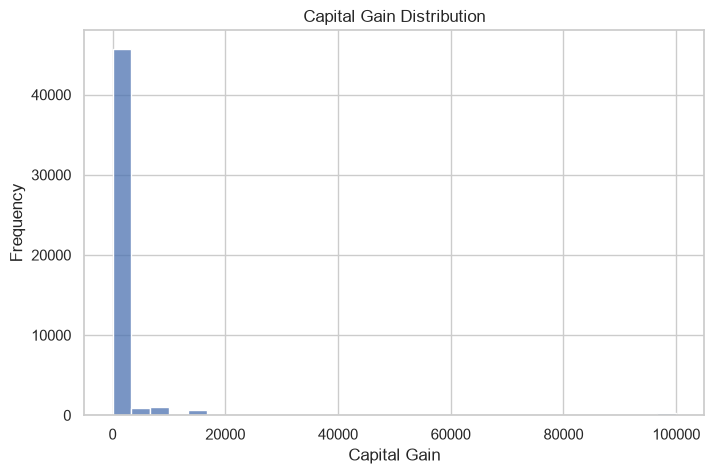

In [77]:
# =====================================================
# 24. CAPITAL GAIN DISTRIBUTION
# =====================================================
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="capital-gain",
    bins=30)
plt.title("Capital Gain Distribution")
plt.xlabel("Capital Gain")
plt.ylabel("Frequency")
plt.show()

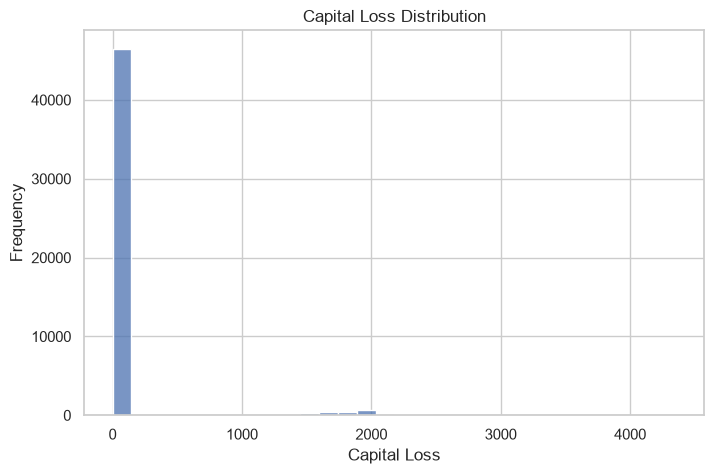

In [78]:
# =====================================================
# 25. CAPITAL LOSS DISTRIBUTION
# =====================================================
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="capital-loss",
    bins=30)

plt.title("Capital Loss Distribution")
plt.xlabel("Capital Loss")
plt.ylabel("Frequency")
plt.show()

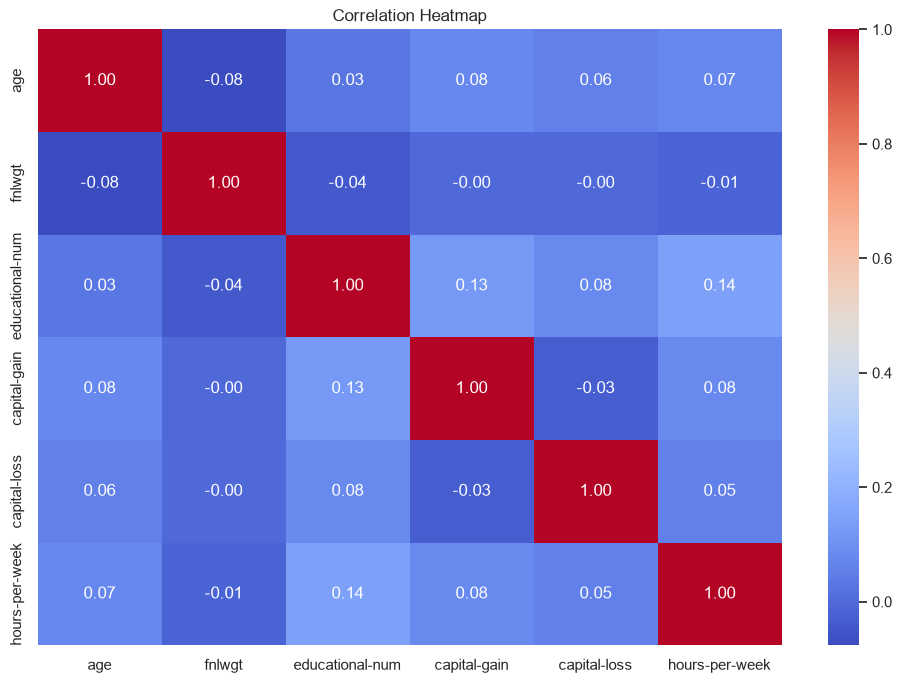

In [79]:
# =====================================================
# 26. CORRELATION HEATMAP
# =====================================================
plt.figure(figsize=(12, 8))
correlation = df_clean.select_dtypes(
    include=np.number
).corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [80]:
# =====================================================
# 27. GROUP ANALYSIS
# =====================================================
print("\nAverage Age by Income:")
print(df_clean.groupby("income")["age"].mean())

print("\nAverage Working Hours by Income:")
print(df_clean.groupby("income")["hours-per-week"].mean())

print("\nAverage Education Number by Income:")
print(df_clean.groupby("income")["educational-num"].mean())


Average Age by Income:
income
<=50K    36.882751
>50K     44.276004
Name: age, dtype: float64

Average Working Hours by Income:
income
<=50K    38.842976
>50K     45.454584
Name: hours-per-week, dtype: float64

Average Education Number by Income:
income
<=50K     9.598938
>50K     11.603287
Name: educational-num, dtype: float64


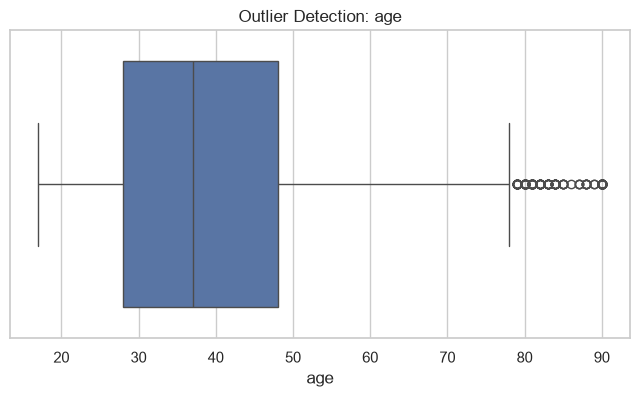

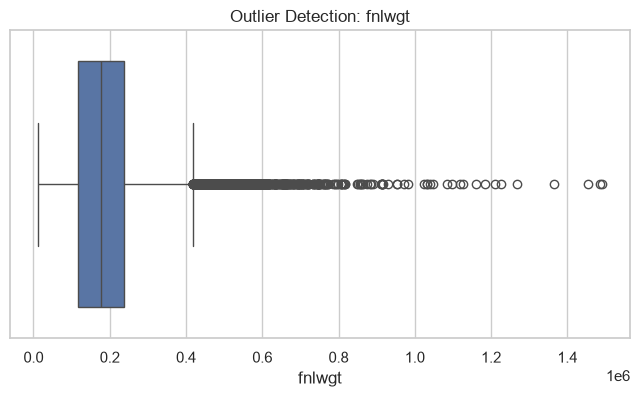

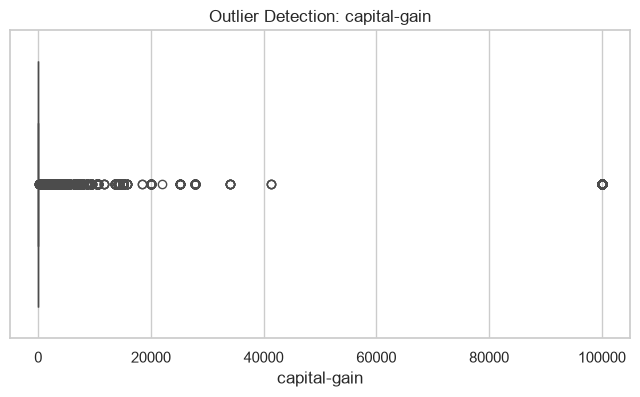

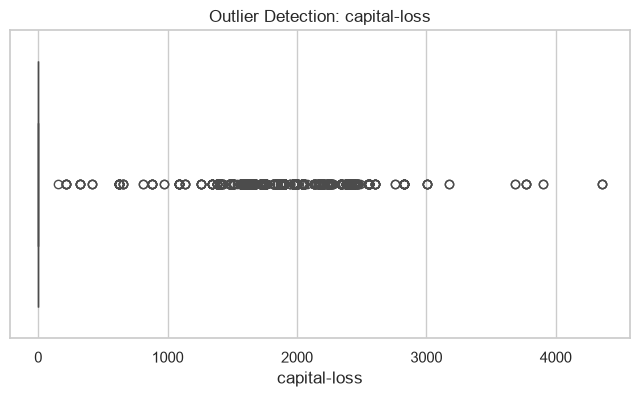

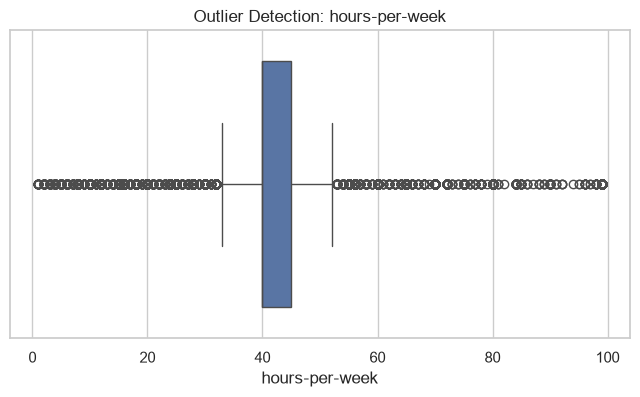

In [81]:
# =====================================================
# 28. OUTLIER DETECTION USING BOXPLOT
# =====================================================
outlier_columns = [
    "age",
    "fnlwgt",
    "capital-gain",
    "capital-loss",
    "hours-per-week"]
for column in outlier_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_clean, x=column)
    plt.title("Outlier Detection: " + column)
    plt.show()

In [82]:
# =====================================================
# 29. FINAL DATA QUALITY CHECK
# =====================================================
print("\n========== FINAL DATA QUALITY REPORT ==========")
print("\nFinal Dataset Shape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nTotal Missing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nFinal Data Types:")
print(df_clean.dtypes)

print("\nFirst 5 Rows:")
print(df_clean.head())


========== FINAL DATA QUALITY REPORT ==========

Final Dataset Shape:
(48790, 15)

Missing Values:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0

Final Data Types:
age                int64
workclass            str
fnlwgt             int64
education            str
educational-num    int64
marital-status       str
occupation           str
relationship         str
race                 str
gender               str
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country       str
income               str
dtype: object

First 5 Rows:
   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802

In [83]:
# =====================================================
# 30. SAVE CLEANED DATASET
# =====================================================
df_clean.to_csv(
    "Adult_Census_Cleaned.csv",
    index=False)
print("\nAdult Census Cleaned Dataset Saved Successfully!")


Adult Census Cleaned Dataset Saved Successfully!
